# Random Forest and AdaBoost

Blood pressure estimation from PPG and ECG signals.

## Model

Each prediction uses a five-second window of PPG and ECG. The signals are cleaned and converted into 91 features describing pulse shape, heart rate and timing.

Random Forest averages predictions from 200 decision trees. AdaBoost builds trees in sequence, giving more weight to examples that earlier trees predicted poorly.

Training used 11,291 windows from 1,308 recordings. Validation used 857 windows from 100 recordings. Recordings and detected overlaps were kept together when splitting the data.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from demo_helpers import show_example

assets = Path('assets')
model = joblib.load(assets / 'rf_ecg.joblib')
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.titleweight': 'bold'})
print('Ready: trained Random Forest loaded. No retraining is needed for this demo.')

Ready: trained Random Forest loaded. No retraining is needed for this demo.


## Example prediction

PPG and ECG are the inputs. ABP is the measured blood pressure, shown for comparison. The table compares the model’s estimate with the reference value.

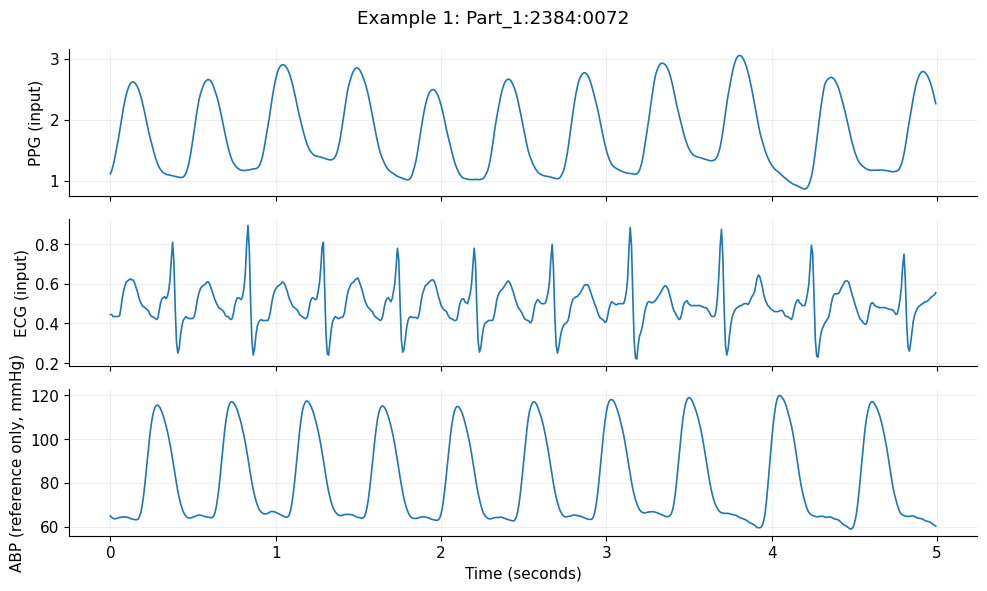

PPG template quality: 1.00; PPG peaks: 11; ECG R peaks: 10


,Target,Reference (mmHg),RF prediction (mmHg),Absolute error (mmHg)
0,Systolic,117.13,125.19,8.06
1,Diastolic,63.25,68.03,4.78


In [2]:
EXAMPLE = 1  # Choose 1–8, then rerun this cell.
display(show_example(EXAMPLE))

## Random Forest results

MAE is the average absolute error in mmHg. Lower values mean predictions are closer to the measured pressure.

,Average error / MAE (mmHg),RMSE (mmHg),Within 10 mmHg (%)
Systolic (upper number),15.03,20.43,49.01
Diastolic (lower number),7.63,10.92,77.83


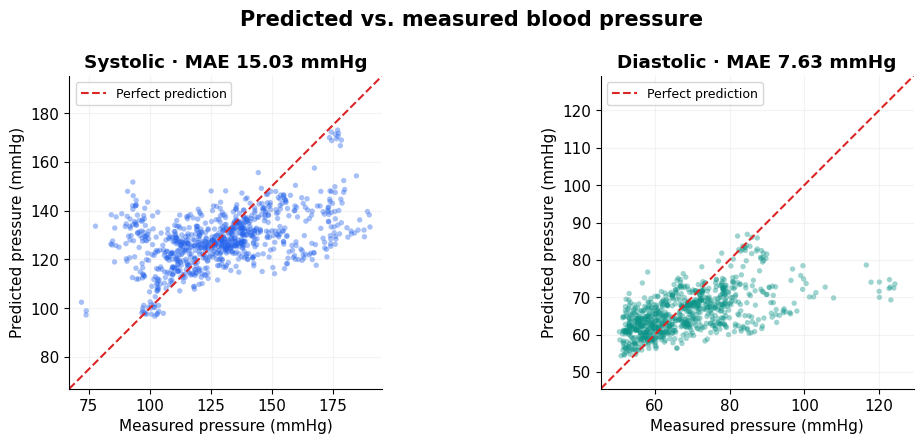

In [3]:
metrics = pd.read_csv(assets / 'validation_metrics.csv')
rf = metrics[metrics['modality'].eq('PPG + ECG')].set_index('target').loc[['sbp', 'dbp']]
summary = rf[['mae_mmHg', 'rmse_mmHg', 'within_10_mmHg_pct']].copy()
summary.index = ['Systolic (upper number)', 'Diastolic (lower number)']
summary.columns = ['Average error / MAE (mmHg)', 'RMSE (mmHg)', 'Within 10 mmHg (%)']
display(summary.round(2))

pred = pd.read_csv(assets / 'validation_predictions.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, target, title, color in zip(axes, ['sbp', 'dbp'], ['Systolic', 'Diastolic'], ['#2563eb', '#0d9488']):
    actual, estimated = pred[target], pred['prediction_' + target]
    limits = [min(actual.min(), estimated.min()) - 5, max(actual.max(), estimated.max()) + 5]
    ax.scatter(actual, estimated, s=15, alpha=.4, color=color, edgecolors='none')
    ax.plot(limits, limits, '--', color='#dc2626', label='Perfect prediction')
    ax.set(xlim=limits, ylim=limits, xlabel='Measured pressure (mmHg)', ylabel='Predicted pressure (mmHg)',
           title=f'{title} · MAE {rf.loc[target, "mae_mmHg"]:.2f} mmHg')
    ax.set_aspect('equal', adjustable='box')
    ax.legend(fontsize=9)
    ax.grid(alpha=.15)
fig.suptitle('Predicted vs. measured blood pressure', fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(assets / 'prediction_summary.png', dpi=170, bbox_inches='tight')
plt.show()

Each dot represents one validation window. The red line shows a perfect prediction. The model tends to overestimate lower pressures and underestimate higher pressures.

## Random Forest vs. AdaBoost

Both models were evaluated on the same validation windows and features for each input setting.

Systolic MAE  Diastolic MAE
Model         Inputs                                
Random Forest PPG               15.76           8.34
              PPG + ECG         15.03           7.63
AdaBoost      PPG               17.74           8.94
              PPG + ECG         17.76           8.84

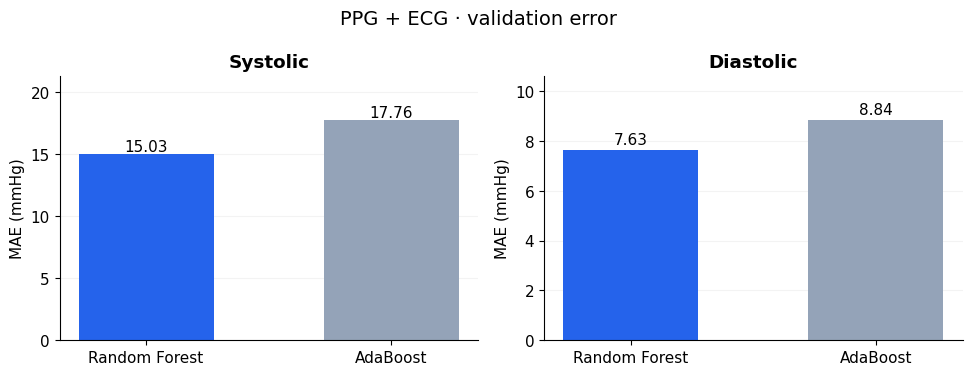

In [4]:
comparison = pd.read_csv(assets / 'model_comparison.csv')
mae = comparison.pivot(index=['model', 'modality'], columns='target', values='mae_mmHg')
mae = mae.reindex(pd.MultiIndex.from_tuples([
    ('Random Forest', 'PPG'), ('Random Forest', 'PPG + ECG'),
    ('AdaBoost', 'PPG'), ('AdaBoost', 'PPG + ECG')], names=['Model', 'Inputs']))
mae = mae.rename(columns={'sbp': 'Systolic MAE', 'dbp': 'Diastolic MAE'})[['Systolic MAE', 'Diastolic MAE']]
mae.columns.name = None
display(mae.round(2))

both = comparison[comparison['modality'].eq('PPG + ECG')]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, target, title in zip(axes, ['sbp', 'dbp'], ['Systolic', 'Diastolic']):
    values = both[both['target'].eq(target)].set_index('model').loc[['Random Forest', 'AdaBoost'], 'mae_mmHg']
    bars = ax.bar(values.index, values.values, color=['#2563eb', '#94a3b8'], width=.55)
    for bar, value in zip(bars, values.values):
        ax.text(bar.get_x() + bar.get_width()/2, value + .25, f'{value:.2f}', ha='center')
    ax.set(title=title, ylabel='MAE (mmHg)', ylim=(0, max(values) * 1.2))
    ax.set_axisbelow(True); ax.grid(axis='y', alpha=.15)
fig.suptitle('PPG + ECG · validation error', fontsize=14)
fig.tight_layout()
fig.savefig(assets / 'model_comparison.png', dpi=170, bbox_inches='tight')
plt.show()

Random Forest had lower error than AdaBoost for both pressures. With PPG and ECG, its systolic MAE was **15.03 mmHg** and diastolic MAE was **7.63 mmHg**. **77.8%** of diastolic predictions were within 10 mmHg of the reference.

These are development validation results. Patient IDs were unavailable, so performance on new patients has not been established.

## Bland–Altman plots

These plots show prediction error across the pressure range. The solid line is the average signed error. Dashed lines show that average ± 1.96 standard deviations; they summarize the observed errors and are not clinical acceptance thresholds.

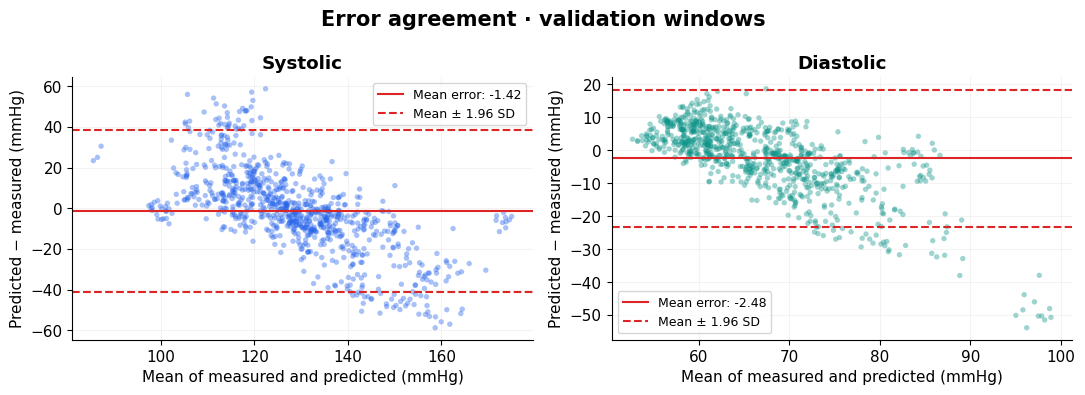

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, target, title, color in zip(axes, ['sbp', 'dbp'], ['Systolic', 'Diastolic'], ['#2563eb', '#0d9488']):
    actual, estimated = pred[target], pred['prediction_' + target]
    error = estimated - actual
    bias, sd = error.mean(), error.std(ddof=1)
    ax.scatter((actual + estimated) / 2, error, s=15, alpha=.4, color=color, edgecolors='none')
    ax.axhline(bias, color='#dc2626', label=f'Mean error: {bias:.2f}')
    ax.axhline(bias + 1.96 * sd, color='#dc2626', linestyle='--', label='Mean ± 1.96 SD')
    ax.axhline(bias - 1.96 * sd, color='#dc2626', linestyle='--')
    ax.set(title=title, xlabel='Mean of measured and predicted (mmHg)', ylabel='Predicted − measured (mmHg)')
    ax.legend(fontsize=9); ax.grid(alpha=.15)
fig.suptitle('Error agreement · validation windows', fontsize=15, fontweight='bold')
fig.tight_layout()
fig.savefig(assets / 'error_agreement.png', dpi=170, bbox_inches='tight')
plt.show()